In [1]:
from astropy.io import fits
from spectral_cube import SpectralCube
import astropy.units as u
from astropy.wcs import WCS
import numpy as np

In [2]:
import sys
from pathlib import Path
sys.path.append(str(Path().resolve() / 'py_modules')) 
from spectral_lines import LINES, print_available_lines
from astronomical_instruments import INSTRUMENTS, print_available_instruments
from astronomical_objects import OBJECTS, print_available_objects

In [3]:
cfg = LINES["Halpha"]

plot_label = cfg.plot_label
rest_wavelength = cfg.rest_wavelength
wavelength_id    = cfg.wavelength_id
element = cfg.element
ion = cfg.ion
transition_id = cfg.transition_id

print(plot_label)
print(rest_wavelength)
print(wavelength_id)
print(element)
print(ion)
print(transition_id)

H$\alpha$
6562.79
6563
H
Ha
H_I-6563


In [4]:
nebula = OBJECTS["30Doradus"]

catalog_name = nebula.catalog_name
common_name  = nebula.common_name
object_type  = nebula.object_type
object_id    = nebula.object_id
dist = nebula.distance_pc
pc         = nebula.pc_per_arcsec

print(catalog_name)
print(common_name)
print(object_type)
print(object_id)
print(dist)
print(pc)

NGC 2070
30 Doradus
H II region
30Dor
50000
0.24240684055476797


In [5]:
inst_id = 'FLAMES'   
inst = 'FLAMES'
pix  = 20

In [6]:
bins = 0
name_id =  inst_id + '-' + object_id + '-' + ion + '-' + 'bin' + str(bins)
name_file = name_id
print(name_id)

FLAMES-30Dor-Ha-bin0


In [7]:
s0_        = 0.9    # proposed seeing
s0         = (s0_*pc) / 2.355    # RMS seeing [parsecs]

In [8]:
sb = fits.open('results_moments/FLAMES_30Dor_Halpha_regular_M0_windows.fits' )[0].data.astype(float)
vv = fits.open('results_moments/FLAMES_30Dor_Halpha_regular_VMEAN_windows.fits' )[0].data.astype(float)
ss = fits.open('results_moments/FLAMES_30Dor_Halpha_regular_SIGMA_windows.fits' )[0].data.astype(float)

In [9]:
filename = "results_moments/FLAMES_30Dor_Halpha_regular_M0_windows.fits"

with fits.open(filename) as hdul:
    sb = hdul[0].data.astype(float)
    hdr = hdul[0].header.copy()

# Display the full header
print(hdr.tostring(sep="\n"))

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                  -32 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                   32                                                  
NAXIS2  =                   30                                                  
WCSAXES =                    2 / Number of coordinate axes                      
CRPIX1  =                 14.0 / Pixel coordinate of reference point            
CRPIX2  =                  6.0 / Pixel coordinate of reference point            
PC1_1   =    -0.00557723991055 / Coordinate transformation matrix element       
PC1_2   =    1.95156391047E-17 / Coordinate transformation matrix element       
PC2_1   =    1.90819582357E-17 / Coordinate transformation matrix element       
PC2_2   =     0.00555253180951 / Coordinate transformation matrix element       
CDELT1  =                  1

In [10]:
wcs = WCS(hdr).celestial

print(wcs)
print("Has celestial WCS:", wcs.has_celestial)

# Header containing the spatial WCS, for later export
wcs_header = wcs.to_header()

WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN' 'DEC--TAN' 
CRVAL : 84.7217102051 -69.1499786377 
CRPIX : 14.0 6.0 
PC1_1 PC1_2  : -0.00557723991055 1.95156391047e-17 
PC2_1 PC2_2  : 1.90819582357e-17 0.00555253180951 
CDELT : 1.0 1.0 
NAXIS : 32  30
Has celestial WCS: True


In [11]:
#hdul_mask = fits.open('fits_ready/mask_cont.fits')
#mask = hdul_mask['MASK'].data.astype(bool)

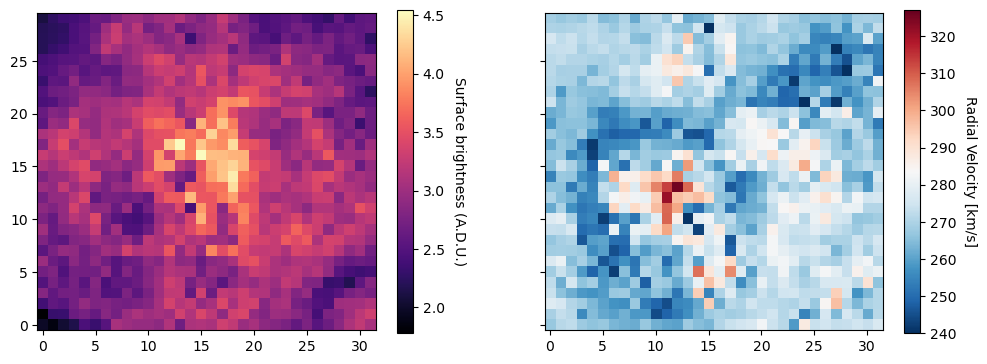

In [12]:
import matplotlib.pyplot as plt

fig, (axx, ax) = plt.subplots(
    1,
    2,
    sharey=True,
    figsize=(12, 6),
)
imshow_kwds = dict(origin="lower", cmap="RdBu_r")
imshow_kwds2 = dict(origin="lower", cmap="magma")
im = ax.imshow(vv,vmin = 240, vmax=327,**imshow_kwds)
#im.cmap.set_bad(color='gray')
cbar = fig.colorbar(im, ax=[ax], shrink=0.7)
cbar.set_label("Radial Velocity [km/s]", rotation=270, labelpad=15)
im = axx.imshow(np.log10(sb), **imshow_kwds2)
#im.cmap.set_bad(color='gray')
cbar = fig.colorbar(im, ax=[axx], shrink=0.7)
cbar.set_label("Surface brightness (A.D.U.)", rotation=270, labelpad=15)
#fig.suptitle(plot_label, y=0.8)

#plt.savefig('Imgs/' + name_id + '.jpg', bbox_inches='tight')

Continuum

In [13]:
#vv = np.where(mask, vv, np.nan)     
#sb = np.where(mask, sb, np.nan) 

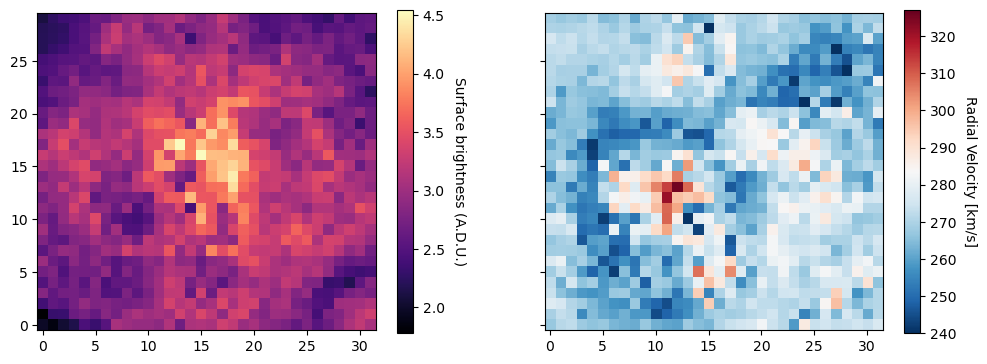

In [14]:
fig, (axx, ax) = plt.subplots(
    1,
    2,
    sharey=True,
    figsize=(12, 6),
)
imshow_kwds = dict(origin="lower", cmap="RdBu_r")
imshow_kwds2 = dict(origin="lower", cmap="magma")
im = ax.imshow(vv,vmin = 240, vmax=327,**imshow_kwds)
#im.cmap.set_bad(color='gray')
cbar = fig.colorbar(im, ax=[ax], shrink=0.7)
cbar.set_label("Radial Velocity [km/s]", rotation=270, labelpad=15)
im = axx.imshow(np.log10(sb), **imshow_kwds2)
#im.cmap.set_bad(color='gray')
cbar = fig.colorbar(im, ax=[axx], shrink=0.7)
cbar.set_label("Surface brightness (A.D.U.)", rotation=270, labelpad=15)
#fig.suptitle(plot_label, y=0.8)

#plt.savefig('Imgs/' + name_id + '.jpg', bbox_inches='tight')

In [15]:
## Replace spurious values in the arrays
#m = ~np.isfinite(sb*vv*ss) | (sb < 0.0)

#sb[m] = 0.0
#vv[m] = np.nanmean(vv)
#ss[m] = 0.0
#sb /= sb.max()

#good = (~m) & (sb > 0.001)

In [16]:
#vv_m = np.where(good, vv, np.nan)     
#sb_m = np.where(good, sb, np.nan)
#ss_m = np.where(good, ss, np.nan)

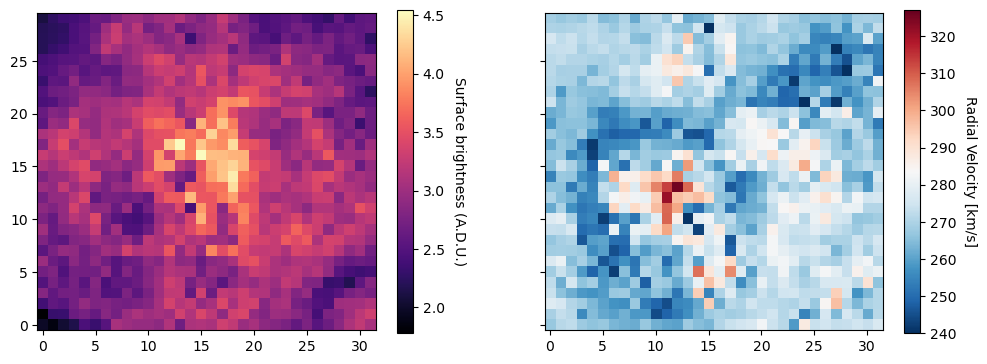

In [17]:
import matplotlib.pyplot as plt

fig, (axx, ax) = plt.subplots(
    1,
    2,
    sharey=True,
    figsize=(12, 6),
)
imshow_kwds = dict(origin="lower", cmap="RdBu_r")
imshow_kwds2 = dict(origin="lower", cmap="magma")
im = ax.imshow(vv,vmin = 240, vmax=327,**imshow_kwds)
im.cmap.set_bad(color='gray')
cbar = fig.colorbar(im, ax=[ax], shrink=0.7)
cbar.set_label("Radial Velocity [km/s]", rotation=270, labelpad=15)
im = axx.imshow(np.log10(sb), **imshow_kwds2)
im.cmap.set_bad(color='gray')
cbar = fig.colorbar(im, ax=[axx], shrink=0.7)
cbar.set_label("Surface brightness (A.D.U.)", rotation=270, labelpad=15)
#fig.suptitle(plot_label, y=0.8)

#plt.savefig('Imgs/' + name_id + '.jpg', bbox_inches='tight')

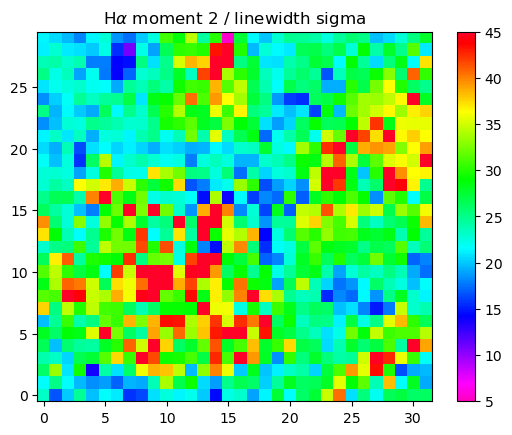

In [18]:
plt.imshow(ss,vmin = 5, vmax=45, origin="lower", cmap='gist_rainbow_r')
plt.colorbar()
plt.title(r"H$\alpha$ moment 2 / linewidth sigma")
plt.show()

Text(0.5, 1.0, 'Ha Flux')

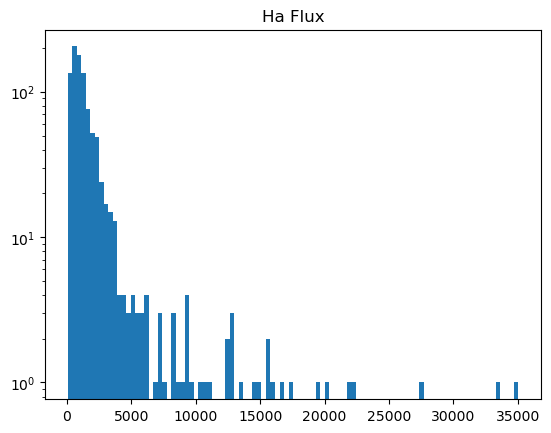

In [19]:
fig, ax = plt.subplots()
plt.hist(sb[np.isfinite(sb)] , bins=100)
ax.set_yscale("log")
ax.set_title('Ha Flux')

Text(0.5, 1.0, 'Ha velocity')

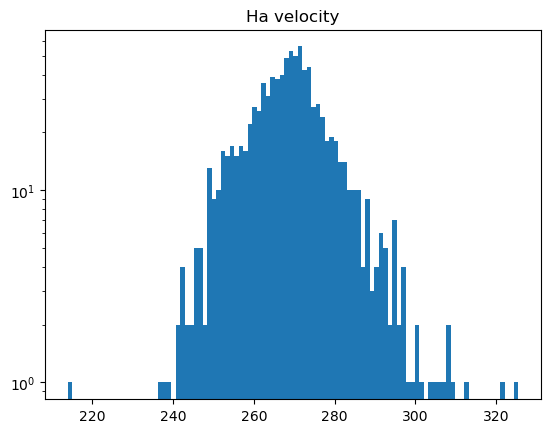

In [20]:
fig, ax = plt.subplots()
plt.hist(vv[np.isfinite(vv)& (np.abs(vv) < 1000)] , bins=100)
ax.set_yscale("log")
ax.set_title('Ha velocity')

Text(0.5, 1.0, 'Sigma velocity')

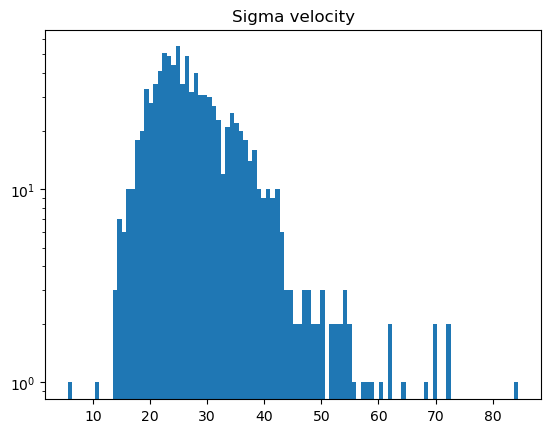

In [21]:
fig, ax = plt.subplots()
plt.hist(ss[np.isfinite(ss)& (np.abs(ss) < 500)] , bins=100)
ax.set_yscale("log")
ax.set_title('Sigma velocity')

In [22]:
mask_vv = (vv > 220) & (vv < 340)

In [23]:
vv_m = np.where(mask_vv, vv, np.nan)     
sb_m = np.where(mask_vv, sb, np.nan)
ss_m = np.where(mask_vv, ss, np.nan)

Text(0.5, 1.0, 'Ha velocity')

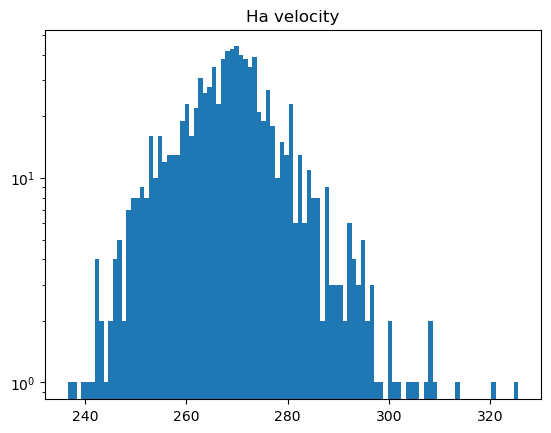

In [24]:
fig, ax = plt.subplots()
plt.hist(vv_m[np.isfinite(vv_m)& (np.abs(vv_m) < 1000)] , bins=100)
ax.set_yscale("log")
ax.set_title('Ha velocity')

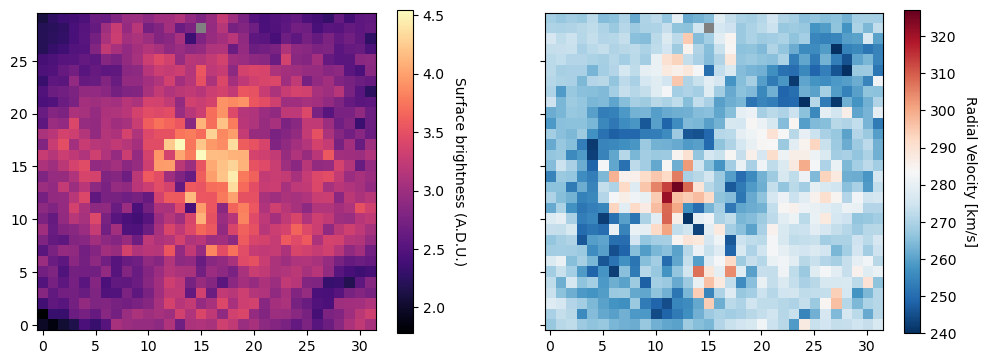

In [25]:
import matplotlib.pyplot as plt

fig, (axx, ax) = plt.subplots(
    1,
    2,
    sharey=True,
    figsize=(12, 6),
)
imshow_kwds = dict(origin="lower", cmap="RdBu_r")
imshow_kwds2 = dict(origin="lower", cmap="magma")
im = ax.imshow(vv_m,vmin = 240, vmax=327,**imshow_kwds)
im.cmap.set_bad(color='gray')
cbar = fig.colorbar(im, ax=[ax], shrink=0.7)
cbar.set_label("Radial Velocity [km/s]", rotation=270, labelpad=15)
im = axx.imshow(np.log10(sb_m), **imshow_kwds2)
im.cmap.set_bad(color='gray')
cbar = fig.colorbar(im, ax=[axx], shrink=0.7)
cbar.set_label("Surface brightness (A.D.U.)", rotation=270, labelpad=15)
#fig.suptitle(plot_label, y=0.8)

#plt.savefig('Imgs/' + name_id + '.jpg', bbox_inches='tight')

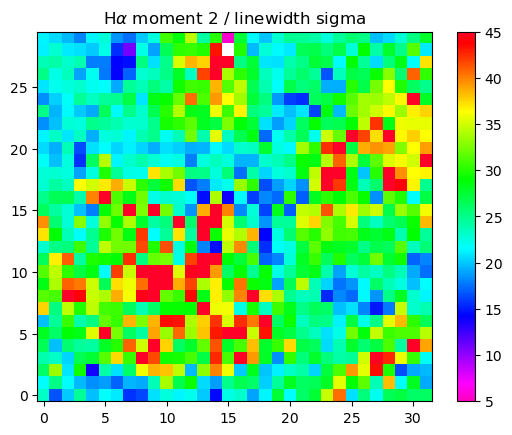

In [26]:
plt.imshow(ss_m,vmin = 5, vmax=45, origin="lower", cmap='gist_rainbow_r')
plt.colorbar()
plt.title(r"H$\alpha$ moment 2 / linewidth sigma")
plt.show()

In [27]:
sb_m1 = np.where(np.isnan(sb_m), 0, sb_m)     
vv_m1 = np.where(np.isnan(vv_m), np.nanmean(vv_m), vv_m)  
ss_m1 = np.where(np.isnan(ss_m), 0, ss_m)  

In [28]:
N = np.sqrt(vv_m1.shape[0] * vv_m1.shape[1]) * pix * pc
#N = np.sqrt(200 * 250) * pix * pc
N

150.21402503605967

In [29]:
import numpy as np
from astropy.wcs.utils import proj_plane_pixel_area

# WCS must correspond to the spatial grid of vv_m1.
ny, nx = vv_m1.shape

# Projected pixel area: deg²/pixel → arcsec²/pixel
pixel_area_arcsec2 = (
    abs(proj_plane_pixel_area(wcs.celestial)) * 3600**2
)

# Full rectangular map area
area_pc2 = nx * ny * pixel_area_arcsec2 * pc**2

# Equivalent-square side length [pc]
N = np.sqrt(area_pc2)

print(f"Map shape: {ny} × {nx}")
print(f"Pixel area: {pixel_area_arcsec2:.4f} arcsec²")
print(f"Map area: {area_pc2:.3f} pc²")
print(f"Equivalent box size: {N:.3f} pc")

Map shape: 30 × 32
Pixel area: 401.3427 arcsec²
Map area: 22639.997 pc²
Equivalent box size: 150.466 pc


In [30]:
sig = np.nanstd(vv)
sig

11.604178085670414

In [31]:
#mask = good & mask_vv & mask
mask = mask_vv 

In [32]:
primary = fits.PrimaryHDU()
# Spatial WCS from the original moment map
wcs_header = wcs.to_header()

primary.header["FILE"]       = (name_file, "Fits file name")
primary.header["NAME_ID"]    = (name_id, "pipeline identifier")
primary.header["REG"]        = (catalog_name, "Region catalog name")
primary.header["NAME_REG"]   = (common_name, "Region name")
primary.header["REG_ID"]     = (object_id, "Region identifier")
primary.header["TYPE_OBJ"]   = (object_type, "Type object")
primary.header["DIST"]       = (dist, "Distance in parsecs")
primary.header["INSTR"]      = (inst, "Instrument")
primary.header["LINE"]       = (plot_label, "Emission line name")
primary.header["LINE_ID"]    = (transition_id, "Emission line identifier")
primary.header["L_REST"]     = (rest_wavelength, "Emission line name")
primary.header["SIG"]        = (sig, "Standard deviation vel map")
primary.header["SIG2"]       = (sig**2, "Vel Variance map")
primary.header["S0"]         = (s0, "Atmospheric seeing")
primary.header["BOX_SIZE"]   = (N* (2**bins), "Observational box_size")
primary.header["PC"]         = (pc, "parsec convertion")
primary.header["PIX"]        = (pix* (2**bins), "Instrument pixel scale")
primary.header["BINSIZE"]    = (bins, "Spatial binning factor")
#hdr["noise"]     = (noise, "Instrumental noise")
#hdr["m3D"]       = (m3D, "k = 3 + m3D")
#hdr["ra"]        = (ra, "Artificial correlation length")
#primary.header["SEED1"]     = (randomseed_vv, "Random seed velocity")
#primary.header["SEED2"]     = (randomseed_sb, "Random seed surfavebrightness")
primary.header["AUTHOR"]     = ("J. Garcia-Vazquez", "File creator")

In [35]:
hdu_m0 = fits.ImageHDU(data=sb_m1, header=wcs_header.copy(), name='MOM0')
hdu_m1 = fits.ImageHDU(data=vv_m1,header=wcs_header.copy(),  name='MOM1')
hdu_m2 = fits.ImageHDU(data=ss_m1, header=wcs_header.copy(), name='MOM2')
hdu_mask = fits.ImageHDU(data=mask.astype(np.uint8) , header=wcs_header.copy(), name='MASK')

In [36]:
hdul = fits.HDUList([primary, hdu_m0, hdu_m1, hdu_m2, hdu_mask])


hdul.writeto('fits_ready/' + name_id + '.fits', overwrite=True)

In [37]:
with fits.open("fits_ready/" + name_id + ".fits") as hdul:
    hdul.info()
    
hdr = hdul[0].header
print(hdr)

Filename: fits_ready/FLAMES-30Dor-Ha-bin0.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      23   ()      
  1  MOM0          1 ImageHDU        30   (32, 30)   float64   
  2  MOM1          1 ImageHDU        30   (32, 30)   float64   
  3  MOM2          1 ImageHDU        30   (32, 30)   float64   
  4  MASK          1 ImageHDU        30   (32, 30)   uint8   
SIMPLE  =                    T / conforms to FITS standard                      BITPIX  =                    8 / array data type                                NAXIS   =                    0 / number of array dimensions                     EXTEND  =                    T                                                  FILE    = 'FLAMES-30Dor-Ha-bin0' / Fits file name                               NAME_ID = 'FLAMES-30Dor-Ha-bin0' / pipeline identifier                          REG     = 'NGC 2070'           / Region catalog name                            NAME_REG= '30 Doradus'    

In [38]:
with fits.open("fits_ready/" + name_id + ".fits") as hdul:
    cube_wcs = WCS(hdul["MOM0"].header).celestial

print(cube_wcs)

WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN' 'DEC--TAN' 
CRVAL : 84.7217102051 -69.1499786377 
CRPIX : 14.0 6.0 
PC1_1 PC1_2  : -0.00557723991055 1.95156391047e-17 
PC2_1 PC2_2  : 1.90819582357e-17 0.00555253180951 
CDELT : 1.0 1.0 
NAXIS : 32  30
